# Hydrogen Bond Analysis — MUC2 Long PTS
## All 3 Systems: Glycosylated, Non-glycosylated, Ext. Glycosylated

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy.stats import gaussian_kde

BASE    = "/home/computer2/analysis_simulations/analysis/hbond_analysis/"
OUT_DIR = os.path.join(BASE, "plots")
os.makedirs(OUT_DIR, exist_ok=True)

CLR_GLY = "#2E86AB"
CLR_NOG = "#A23B72"
CLR_EXT = "#F18F01"

SYS_INFO = [
    ("noglycans",  "Non-glycosylated",  CLR_NOG),
    ("glycans",    "Glycosylated",      CLR_GLY),
    ("xglyc",      "Ext. Glycosylated", CLR_EXT),
]
N_FRAMES = 2381

def load_perframe(sys_key):
    d = np.genfromtxt(BASE + f"hbond_{sys_key}.dat", comments="#")
    return d[:, 1]  # HB count per frame

def load_avg(sys_key):
    rows = []
    with open(BASE + f"hbond_{sys_key}_avg.dat") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            parts = line.split()
            if len(parts) < 7:
                continue
            try:
                rows.append({
                    "Acceptor": parts[0], "DonorH": parts[1], "Donor": parts[2],
                    "Frames": int(parts[3]), "Occ_pct": float(parts[4]) * 100.0,
                    "AvgDist": float(parts[5]), "AvgAng": float(parts[6]),
                    "HBond_ID": f"{parts[0]}_{parts[2]}",
                })
            except (ValueError, IndexError):
                continue
    return pd.DataFrame(rows)

hb_frame = {s: load_perframe(s) for s, *_ in SYS_INFO}
hb_avg   = {s: load_avg(s)      for s, *_ in SYS_INFO}

for s, lbl, _ in SYS_INFO:
    f = hb_frame[s]
    a = hb_avg[s]
    print(f"{lbl:22s}  mean={f.mean():.2f}±{f.std():.2f}  unique pairs={len(a)}  max occ={a['Occ_pct'].max():.1f}%")
print("Ready. Output:", OUT_DIR)

## Figure 1 — Per-Frame H-Bond Count: Distribution & Time Series

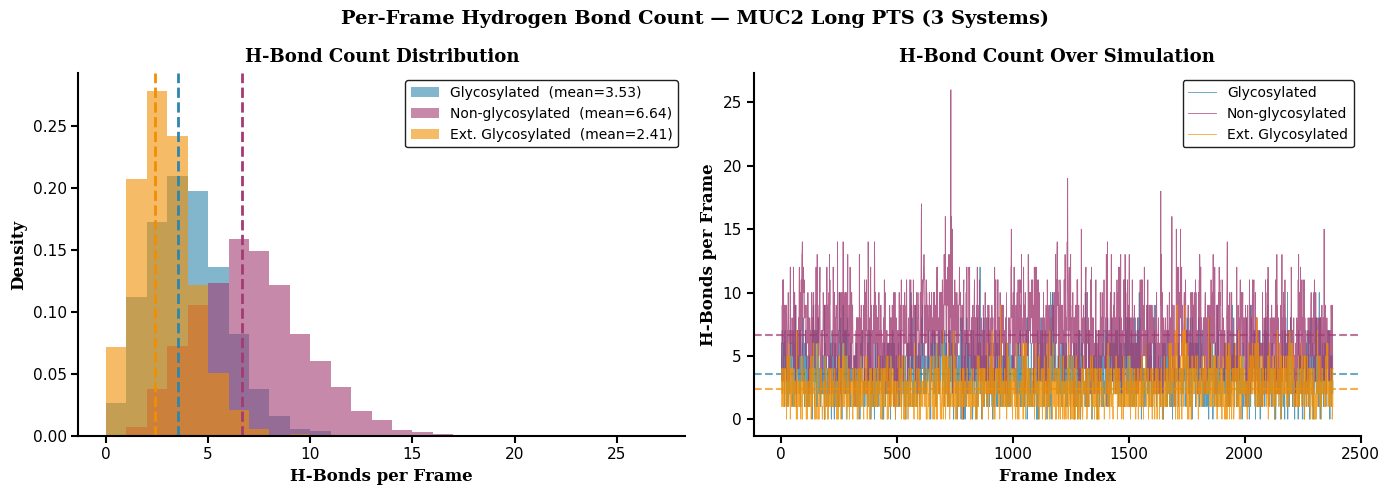

Saved: /home/computer2/analysis_simulations/analysis/hbond_analysis/plots/hbond_perframe_3sys.png


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=100)
fig.set_facecolor("white")

# Left: overlapping histograms
ax = axes[0]
for s, lbl, clr in SYS_INFO:
    hb = hb_frame[s]
    ax.hist(hb, bins=range(0, int(hb.max()) + 2), color=clr, alpha=0.60,
            density=True, label=f"{lbl}  (mean={hb.mean():.2f})")
    ax.axvline(hb.mean(), color=clr, linewidth=2.0, linestyle="--")
ax.set_xlabel("H-Bonds per Frame", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("Density", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
ax.set_title("H-Bond Count Distribution", fontsize=13, fontname="DejaVu Serif", fontweight="bold", pad=8)
ax.legend(fontsize=10, framealpha=0.88, edgecolor="black")
ax.set_facecolor("white")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5); ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=11, length=5, width=1.5, direction="out")

# Right: time series
ax = axes[1]
for s, lbl, clr in SYS_INFO:
    hb = hb_frame[s]
    ax.plot(np.arange(1, N_FRAMES + 1), hb, color=clr, linewidth=0.6, alpha=0.80, label=lbl)
    ax.axhline(hb.mean(), color=clr, linewidth=1.5, linestyle="--", alpha=0.7)
ax.set_xlabel("Frame Index", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("H-Bonds per Frame", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
ax.set_title("H-Bond Count Over Simulation", fontsize=13, fontname="DejaVu Serif", fontweight="bold", pad=8)
ax.legend(fontsize=10, framealpha=0.88, edgecolor="black")
ax.set_facecolor("white")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5); ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=11, length=5, width=1.5, direction="out")

fig.suptitle("Per-Frame Hydrogen Bond Count — MUC2 Long PTS (3 Systems)",
             fontsize=14, fontname="DejaVu Serif", fontweight="bold")
plt.tight_layout()
out = os.path.join(OUT_DIR, "hbond_perframe_3sys.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show(); print(f"Saved: {out}")

## Figure 2 — Mean H-Bond Count Summary (Bar Chart)

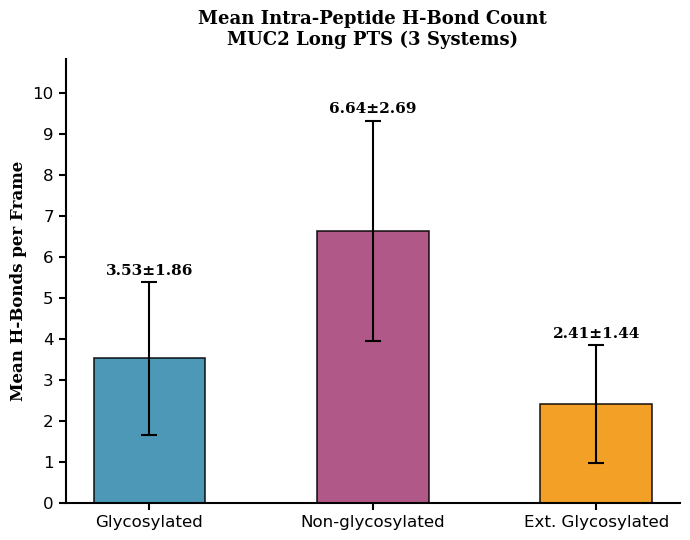

Saved: /home/computer2/analysis_simulations/analysis/hbond_analysis/plots/hbond_mean_bar_3sys.png


In [3]:
fig, ax = plt.subplots(figsize=(7, 5.5), dpi=100)
fig.set_facecolor("white")

labels = [lbl for _, lbl, _ in SYS_INFO]
means  = [hb_frame[s].mean() for s, *_ in SYS_INFO]
stds   = [hb_frame[s].std()  for s, *_ in SYS_INFO]
colors = [clr for _, _, clr in SYS_INFO]

bars = ax.bar(labels, means, yerr=stds, color=colors, alpha=0.85,
              edgecolor="black", linewidth=1.2, width=0.5,
              error_kw=dict(elinewidth=1.5, capsize=6, capthick=1.5, ecolor="black"))

for bar, m, s in zip(bars, means, stds):
    ax.text(bar.get_x() + bar.get_width() / 2, m + s + 0.1,
            f"{m:.2f}±{s:.2f}", ha="center", va="bottom",
            fontsize=11, fontname="DejaVu Serif", fontweight="bold")

ax.set_ylabel("Mean H-Bonds per Frame", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Mean Intra-Peptide H-Bond Count\nMUC2 Long PTS (3 Systems)",
             fontsize=13, fontname="DejaVu Serif", fontweight="bold", pad=10)
ax.set_ylim(0, max(means) + max(stds) + 1.5)
ax.set_facecolor("white")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5); ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=12, length=5, width=1.5, direction="out")
ax.yaxis.set_major_locator(ticker.MultipleLocator(1))
plt.tight_layout()
out = os.path.join(OUT_DIR, "hbond_mean_bar_3sys.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show(); print(f"Saved: {out}")

## Figure 3 — Top H-Bonds by Occupancy (per system)

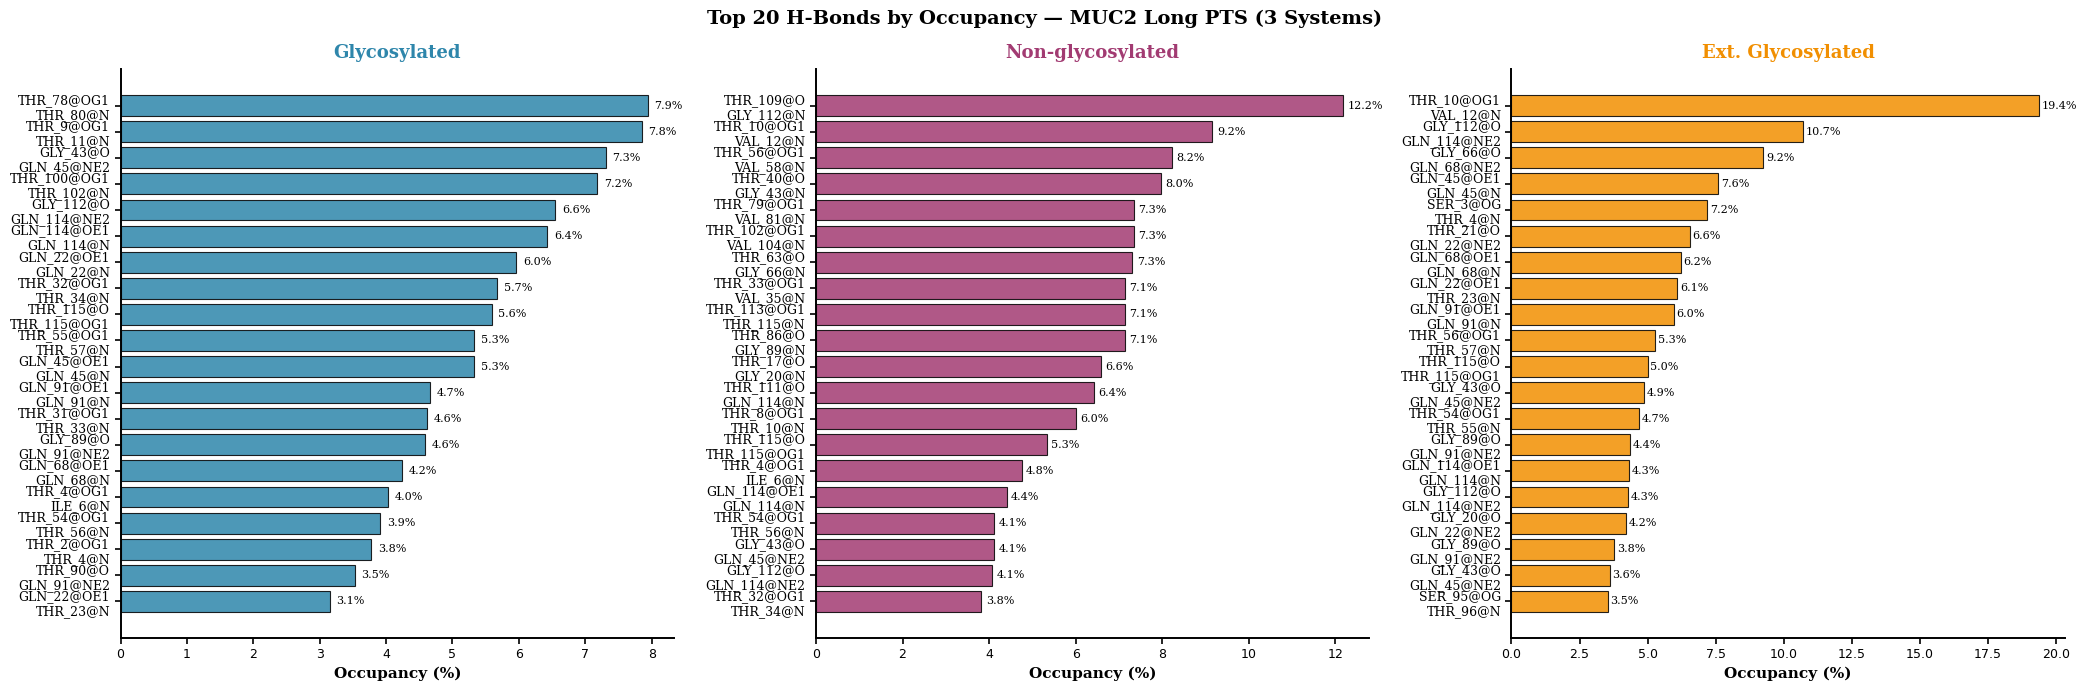

Saved: /home/computer2/analysis_simulations/analysis/hbond_analysis/plots/hbond_top_occupancy_3sys.png


In [4]:
TOP_N = 20
fig, axes = plt.subplots(1, 3, figsize=(21, 7), dpi=100)
fig.set_facecolor("white")

for ax, (s, lbl, clr) in zip(axes, SYS_INFO):
    df = hb_avg[s].nlargest(TOP_N, "Occ_pct").sort_values("Occ_pct")
    pair_labels = [f"{r['Acceptor']}\n{r['Donor']}" for _, r in df.iterrows()]
    bars = ax.barh(range(len(df)), df["Occ_pct"], color=clr, alpha=0.85,
                   edgecolor="black", linewidth=0.8)
    ax.set_yticks(range(len(df)))
    ax.set_yticklabels(pair_labels, fontsize=7, fontname="DejaVu Serif")
    ax.set_xlabel("Occupancy (%)", fontsize=11, fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(lbl, fontsize=13, fontname="DejaVu Serif",
                 fontweight="bold", color=clr, pad=8)
    for bar, val in zip(bars, df["Occ_pct"]):
        ax.text(val + 0.1, bar.get_y() + bar.get_height() / 2,
                f"{val:.1f}%", va="center", ha="left", fontsize=8,
                fontname="DejaVu Serif", color="black")
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.4); ax.spines["bottom"].set_linewidth(1.4)
    ax.tick_params(labelsize=9, length=4, width=1.2, direction="out")

fig.suptitle(f"Top {TOP_N} H-Bonds by Occupancy — MUC2 Long PTS (3 Systems)",
             fontsize=14, fontname="DejaVu Serif", fontweight="bold")
plt.tight_layout()
out = os.path.join(OUT_DIR, "hbond_top_occupancy_3sys.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show(); print(f"Saved: {out}")

## Figure 4 — Occupancy Distribution (all H-bond pairs)

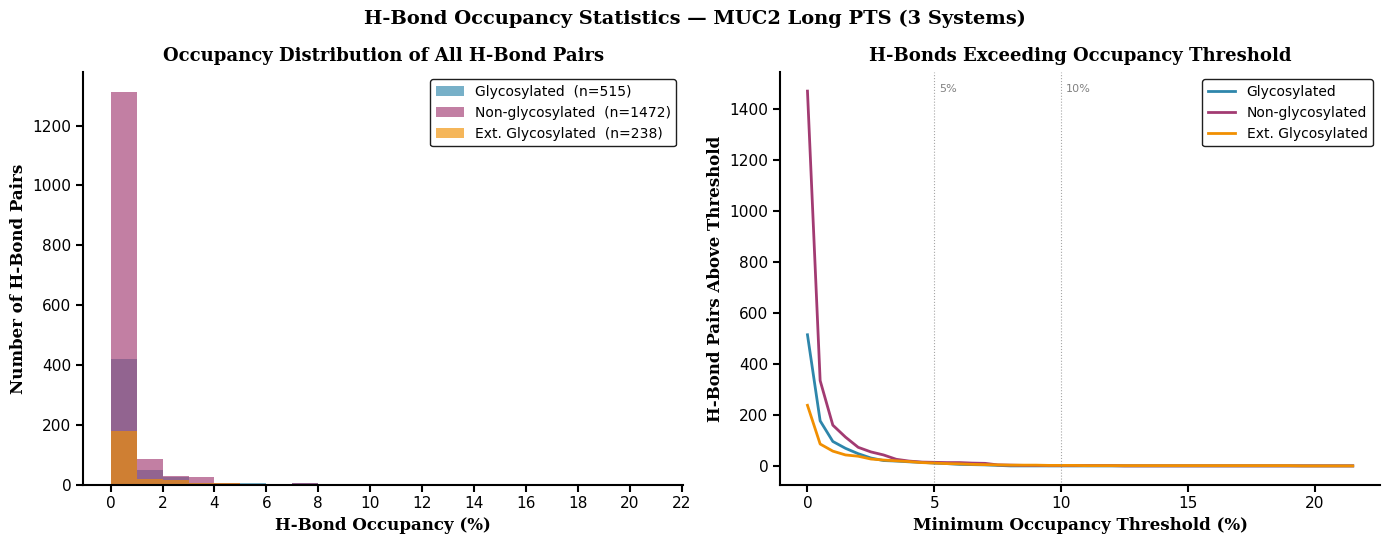

Saved: /home/computer2/analysis_simulations/analysis/hbond_analysis/plots/hbond_occupancy_dist_3sys.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=100)
fig.set_facecolor("white")

# Left: histogram of occupancy %
ax = axes[0]
bins = np.arange(0, 22, 1)
for s, lbl, clr in SYS_INFO:
    occ = hb_avg[s]["Occ_pct"]
    ax.hist(occ, bins=bins, color=clr, alpha=0.65, density=False,
            label=f"{lbl}  (n={len(occ)})")
ax.set_xlabel("H-Bond Occupancy (%)", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("Number of H-Bond Pairs", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Occupancy Distribution of All H-Bond Pairs", fontsize=13,
             fontname="DejaVu Serif", fontweight="bold", pad=8)
ax.legend(fontsize=10, framealpha=0.88, edgecolor="black")
ax.set_facecolor("white")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5); ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=11, length=5, width=1.5, direction="out")
ax.xaxis.set_major_locator(ticker.MultipleLocator(2))

# Right: cumulative % of H-bonds above threshold
ax = axes[1]
thresholds = np.arange(0, 22, 0.5)
for s, lbl, clr in SYS_INFO:
    occ = hb_avg[s]["Occ_pct"]
    frac_above = [(occ >= t).sum() for t in thresholds]
    ax.plot(thresholds, frac_above, color=clr, linewidth=2.0, label=lbl)
ax.axvline(5,  color="gray", linewidth=0.8, linestyle=":", alpha=0.7)
ax.axvline(10, color="gray", linewidth=0.8, linestyle=":", alpha=0.7)
ax.text(5.2,  ax.get_ylim()[1]*0.95 if ax.get_ylim()[1] > 0 else 10, "5%",  fontsize=8, color="gray")
ax.text(10.2, ax.get_ylim()[1]*0.95 if ax.get_ylim()[1] > 0 else 10, "10%", fontsize=8, color="gray")
ax.set_xlabel("Minimum Occupancy Threshold (%)", fontsize=12,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("H-Bond Pairs Above Threshold", fontsize=12,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_title("H-Bonds Exceeding Occupancy Threshold", fontsize=13,
             fontname="DejaVu Serif", fontweight="bold", pad=8)
ax.legend(fontsize=10, framealpha=0.88, edgecolor="black")
ax.set_facecolor("white")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5); ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=11, length=5, width=1.5, direction="out")

fig.suptitle("H-Bond Occupancy Statistics — MUC2 Long PTS (3 Systems)",
             fontsize=14, fontname="DejaVu Serif", fontweight="bold")
plt.tight_layout()
out = os.path.join(OUT_DIR, "hbond_occupancy_dist_3sys.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show(); print(f"Saved: {out}")

## Figure 5 — H-Bond Geometry: Distance vs Angle

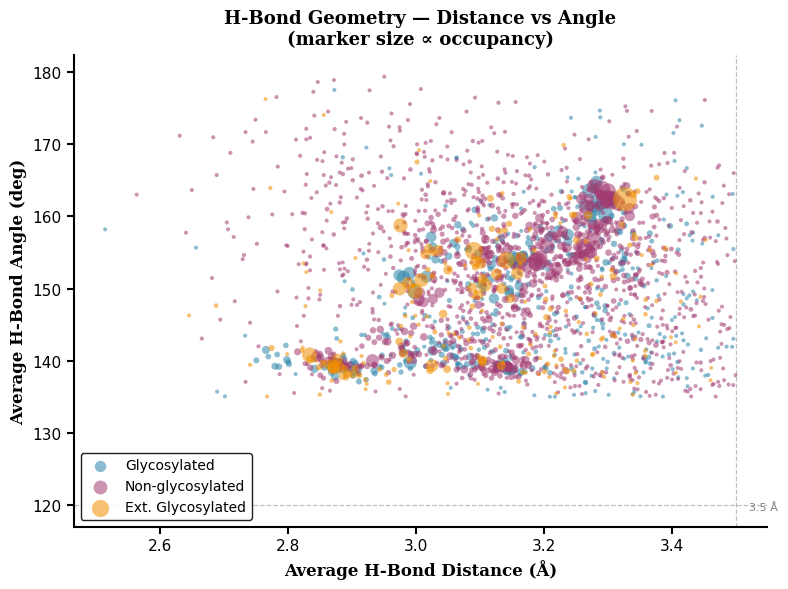

Saved: /home/computer2/analysis_simulations/analysis/hbond_analysis/plots/hbond_geometry_3sys.png


In [6]:
fig, ax = plt.subplots(figsize=(8, 6), dpi=100)
fig.set_facecolor("white")

for s, lbl, clr in SYS_INFO:
    df = hb_avg[s]
    sc = ax.scatter(df["AvgDist"], df["AvgAng"],
                    c=clr, s=df["Occ_pct"] * 15 + 8,
                    alpha=0.55, linewidths=0, label=lbl)

ax.set_xlabel("Average H-Bond Distance (Å)", fontsize=12,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("Average H-Bond Angle (deg)", fontsize=12,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_title("H-Bond Geometry — Distance vs Angle\n(marker size ∝ occupancy)",
             fontsize=13, fontname="DejaVu Serif", fontweight="bold", pad=8)
ax.legend(fontsize=10, framealpha=0.88, edgecolor="black", loc="lower left")

# Reference lines for typical H-bond criteria
ax.axvline(3.5, color="gray", linewidth=0.9, linestyle="--", alpha=0.5)
ax.axhline(120, color="gray", linewidth=0.9, linestyle="--", alpha=0.5)
ax.text(3.52, ax.get_ylim()[0] + 2 if ax.get_ylim()[0] else 120,
        "3.5 Å", fontsize=8, color="gray", va="bottom")

ax.set_facecolor("white")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5); ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=11, length=5, width=1.5, direction="out")

plt.tight_layout()
out = os.path.join(OUT_DIR, "hbond_geometry_3sys.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show(); print(f"Saved: {out}")

## Figure 6 — Unique H-Bond Pairs Summary

H-Bond Pairs by Occupancy Threshold:

           System  ≥0%  ≥1%  ≥5%  ≥10%  ≥15%  ≥20%
     Glycosylated  515   96   11     0     0     0
 Non-glycosylated 1472  160   14     1     0     0
Ext. Glycosylated  238   58   11     2     1     0


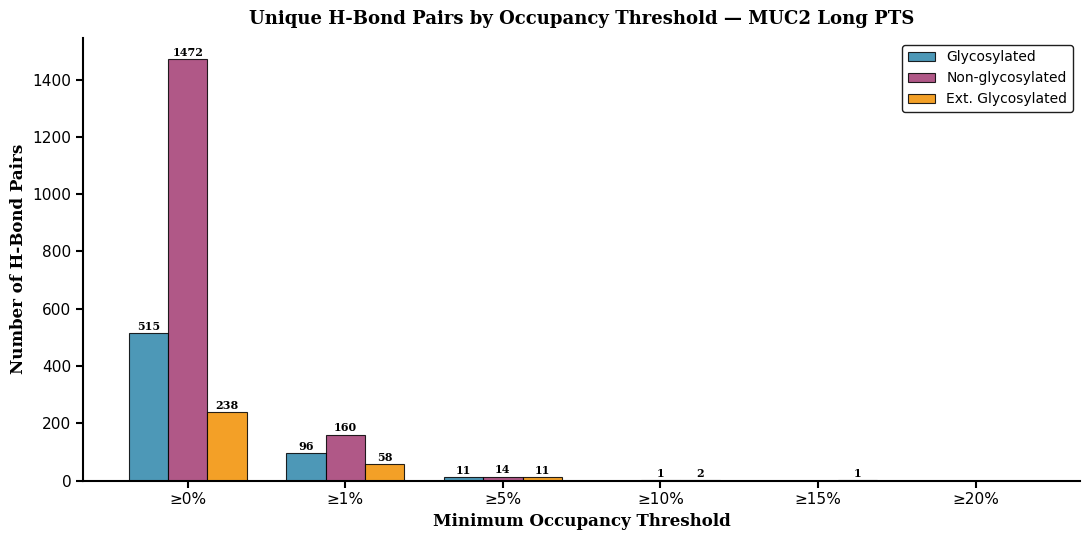

Saved: /home/computer2/analysis_simulations/analysis/hbond_analysis/plots/hbond_unique_pairs_3sys.png


In [7]:
# Count pairs by occupancy threshold for each system
thresholds_pct = [0, 1, 5, 10, 15, 20]
summary_rows = []
for s, lbl, clr in SYS_INFO:
    occ = hb_avg[s]["Occ_pct"]
    row = {"System": lbl, "Color": clr}
    for t in thresholds_pct:
        row[f"≥{t}%"] = (occ >= t).sum()
    summary_rows.append(row)

df_summary = pd.DataFrame(summary_rows)
print("H-Bond Pairs by Occupancy Threshold:\n")
cols_show = ["System"] + [f"≥{t}%" for t in thresholds_pct]
print(df_summary[cols_show].to_string(index=False))

# Grouped bar chart
fig, ax = plt.subplots(figsize=(11, 5.5), dpi=100)
fig.set_facecolor("white")

x = np.arange(len(thresholds_pct))
width = 0.25
for i, (s, lbl, clr) in enumerate(SYS_INFO):
    counts = [df_summary[df_summary["System"] == lbl][f"≥{t}%"].values[0]
              for t in thresholds_pct]
    bars = ax.bar(x + (i - 1) * width, counts, width, color=clr,
                  alpha=0.85, edgecolor="black", linewidth=0.8, label=lbl)
    for bar, cnt in zip(bars, counts):
        if cnt > 0:
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
                    str(cnt), ha="center", va="bottom", fontsize=8,
                    fontname="DejaVu Serif", fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels([f"≥{t}%" for t in thresholds_pct], fontsize=11)
ax.set_xlabel("Minimum Occupancy Threshold", fontsize=12,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("Number of H-Bond Pairs", fontsize=12,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Unique H-Bond Pairs by Occupancy Threshold — MUC2 Long PTS",
             fontsize=13, fontname="DejaVu Serif", fontweight="bold", pad=10)
ax.legend(fontsize=10, framealpha=0.88, edgecolor="black")
ax.set_facecolor("white")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5); ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=11, length=5, width=1.5, direction="out")
ax.yaxis.set_major_locator(ticker.MaxNLocator(8))

plt.tight_layout()
out = os.path.join(OUT_DIR, "hbond_unique_pairs_3sys.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show(); print(f"Saved: {out}")